# Exploring the π0.5 demo results

This notebook needs **no GPU**. It reads the outputs saved by the Kaggle run (`kaggle/run_all.py`) from `results/` and summarizes them.

* **LIBERO** (`results/libero/`): the open-source `pi05_libero` checkpoint controlling a simulated Franka arm.
* **DROID** (`results/droid/`): the `pi05_droid` checkpoint given real robot camera frames and different instructions, to see how the predicted action chunk changes.

In [1]:
import json, pathlib
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, display

ROOT = pathlib.Path('..') if pathlib.Path('../results').exists() else pathlib.Path('.')
libero = pd.DataFrame(json.loads((ROOT / 'results/libero/libero_results.json').read_text()))
droid = json.loads((ROOT / 'results/droid/droid_results.json').read_text())

## 1. LIBERO-Goal: same kitchen, different instructions

Group **A** uses the 10 official LIBERO-Goal instructions (2 trials each). Group **B** rewords 3 of them.

In [2]:
summary = libero.groupby('tag').agg(runs=('success', 'size'), successes=('success', 'sum'),
                                    mean_steps=('steps', 'mean')).round(1)
summary

,runs,successes,mean_steps
tag,,,
A_same_scene,20,20,111.4
B_paraphrase,6,6,94.0


In [3]:
libero[libero.tag == 'A_same_scene'][['official_task', 'trial', 'success', 'steps']]

,official_task,trial,success,steps
0,open the middle drawer of the cabinet,0,True,121
1,open the middle drawer of the cabinet,1,True,113
2,put the bowl on the stove,0,True,83
3,put the bowl on the stove,1,True,127
4,put the wine bottle on top of the cabinet,0,True,78
5,put the wine bottle on top of the cabinet,1,True,86
6,open the top drawer and put the bowl inside,0,True,201
7,open the top drawer and put the bowl inside,1,True,181
8,put the bowl on top of the cabinet,0,True,87
9,put the bowl on top of the cabinet,1,True,85


## 2. Reworded instructions

The wording below differs from the instruction the checkpoint was fine-tuned on.

In [4]:
libero[libero.tag == 'B_paraphrase'][['official_task', 'prompt', 'trial', 'success', 'steps']]

,official_task,prompt,trial,success,steps
20,open the middle drawer of the cabinet,pull open the cabinet's middle drawer,0,True,130
21,open the middle drawer of the cabinet,pull open the cabinet's middle drawer,1,True,110
22,turn on the stove,switch the stove on,0,True,79
23,turn on the stove,switch the stove on,1,True,94
24,put the bowl on the plate,place the bowl onto the plate,0,True,76
25,put the bowl on the plate,place the bowl onto the plate,1,True,75


## 3. DROID: does the instruction change the plan?

For each real scene, the model predicts an action chunk (15 future steps × 8 numbers: 7 joint velocities + gripper). *Spread (same prompt)* is how much the chunk varies when the same prompt is repeated (the model samples from noise). *Difference (between prompts)* is how much it changes when the prompt changes. If the difference is clearly larger than the spread, the instruction is changing the plan.

In [5]:
rows = [{'scene': s['real_task'], 'spread_same_prompt': s['spread_same_prompt'],
         'difference_between_prompts': s['difference_between_prompts']} for s in droid['scenes']]
d = pd.DataFrame(rows).round(3)
d['ratio'] = (d.difference_between_prompts / d.spread_same_prompt).round(2)
d

,scene,spread_same_prompt,difference_between_prompts,ratio
0,Put the marker in the pot,0.047,0.082,1.74
1,Put the candy bar on the left side of the firs...,0.048,0.157,3.27
2,Put one green sachet in the grey bowl.,0.067,0.129,1.93
3,Place the pack of doritos inside the sink,0.039,0.035,0.90


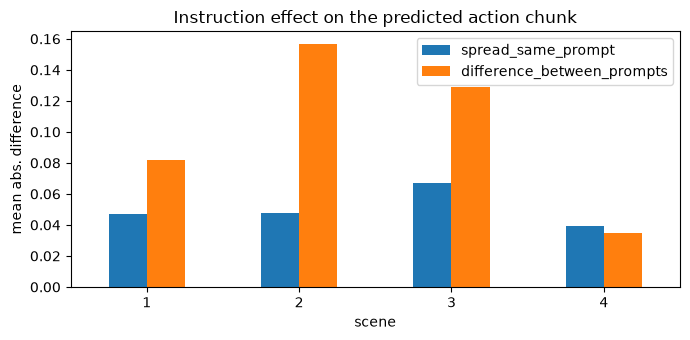

In [6]:
ax = d.set_index(d.index + 1)[['spread_same_prompt', 'difference_between_prompts']].plot.bar(figsize=(7, 3.5), rot=0)
ax.set_xlabel('scene'); ax.set_ylabel('mean abs. difference'); ax.set_title('Instruction effect on the predicted action chunk')
plt.tight_layout()

In [7]:
print(f"model load: {droid['load_seconds']:.0f} s, first inference: {droid['first_infer_seconds']:.1f} s, "
      f"median inference: {droid['median_infer_seconds']:.2f} s (Kaggle T4)")

model load: 35 s, first inference: 10.3 s, median inference: 2.02 s (Kaggle T4)


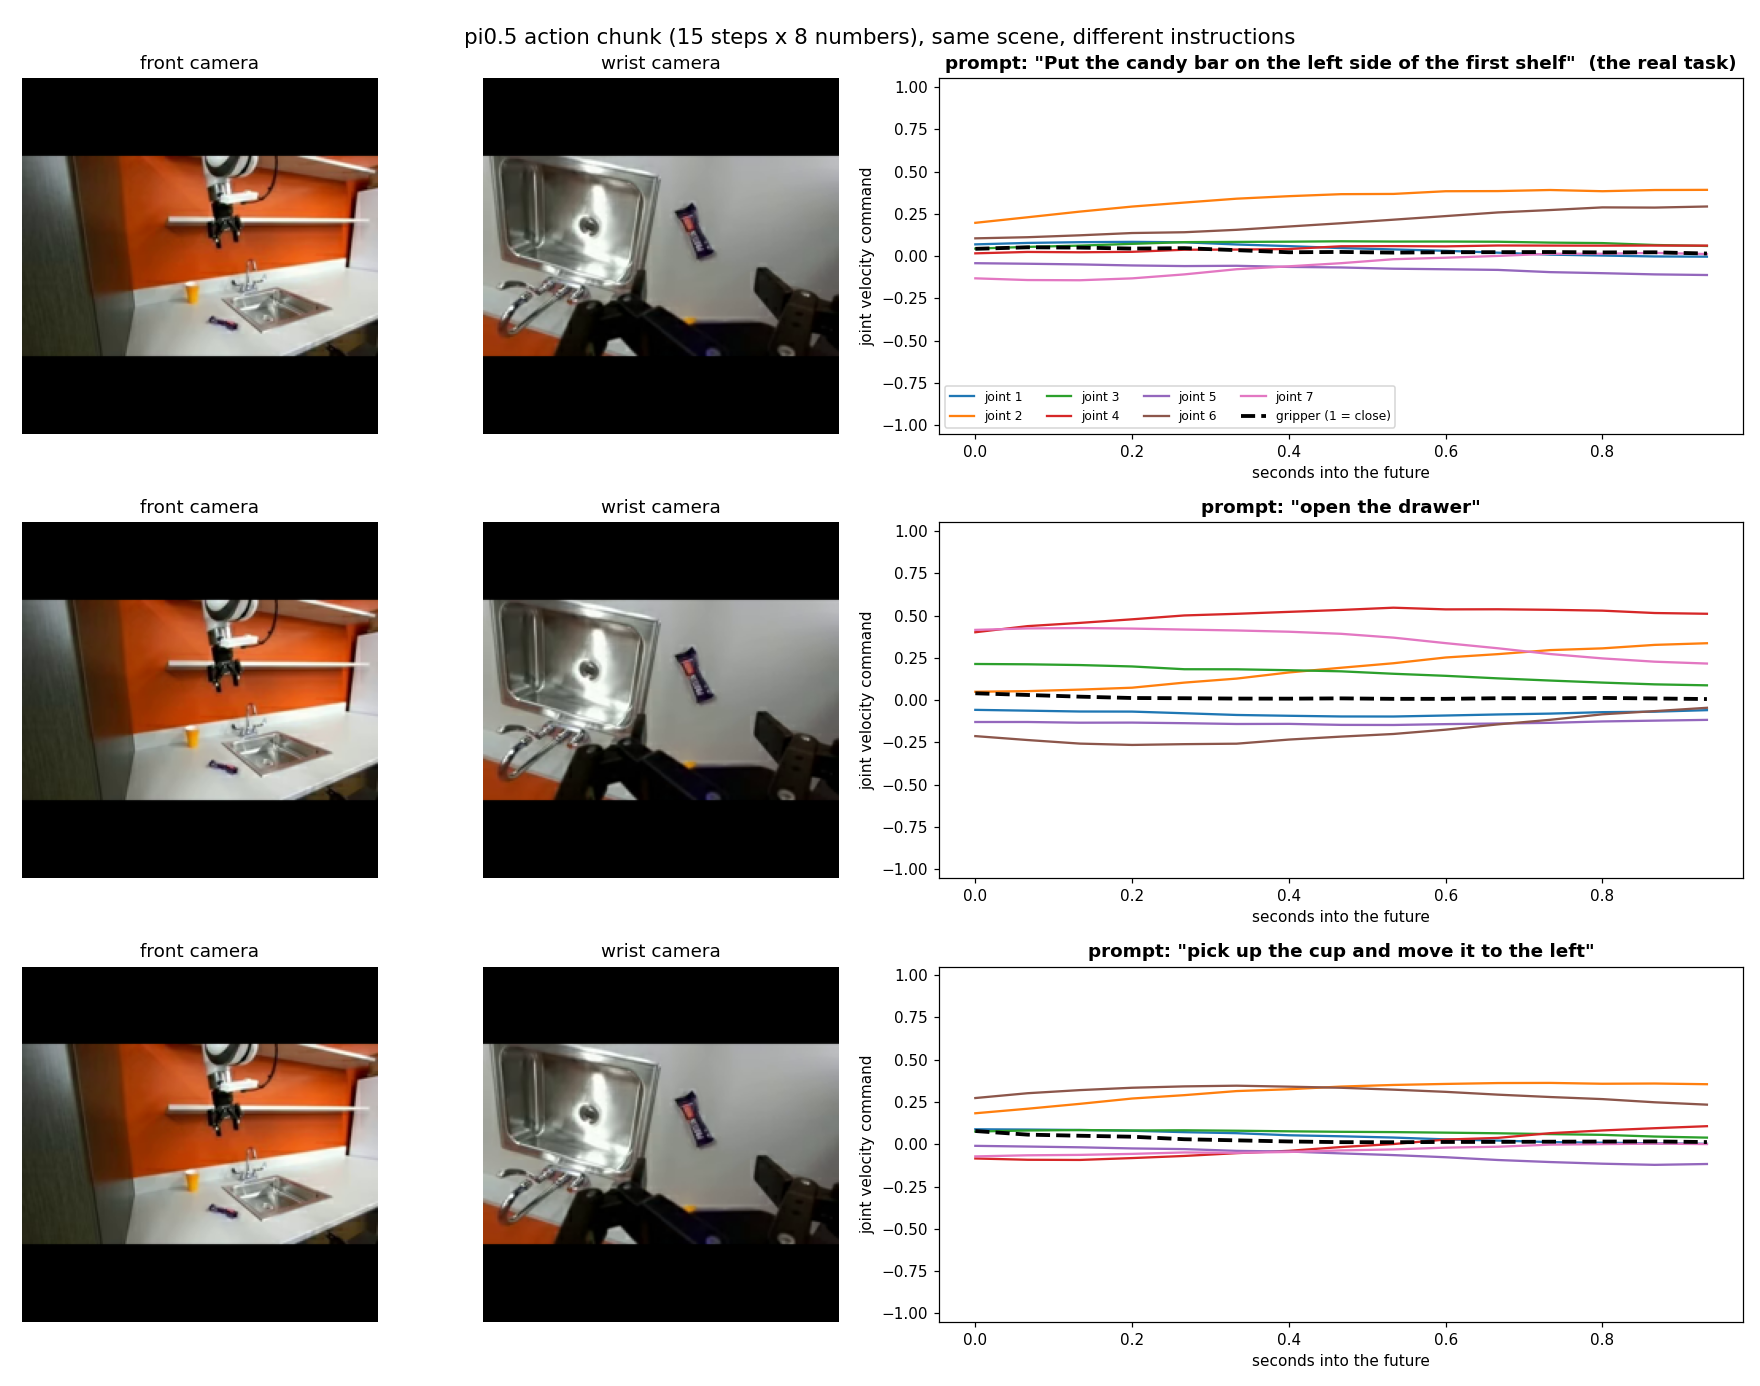

In [8]:
display(Image(filename=str(ROOT / 'results/droid/scene2_prompts.png'), width=900))

## Caveats

* LIBERO results are **in-distribution**: `pi05_libero` was fine-tuned on LIBERO, so 26/26 shows language following, not generalization to new homes.
* The DROID frames come from `lerobot/droid_100`, which is part of DROID (training data for `pi05_droid`), and that dataset stores Cartesian state, so the Franka ready pose was used as the joint state.
* In scene 4 the instruction barely changed the plan (difference ≈ spread).